# Section 2: Product Review Dashboard

**What you'll learn**
- Turn free-text reviews into typed columns: a category, a score, probabilities
- Design a schema where every column is one question
- Ask every question in one request (speculative fan-out)
- Run all 120 reviews at once with `AsyncTypeSafeClient`
- Build a review dashboard with pandas and matplotlib
- Find the low-confidence rows a person should check
- Lab: score sales leads with weights you own

## Setup
- Slides 1-5, covering Schema Design too
- `reviews.csv`: 120 reviews of five Volta products, January to June 2026
- `text` is what we turn into columns

In [1]:
import asyncio
import pandas as pd
from dotenv import load_dotenv
from typesafe_sdk import TypeSafeClient, AsyncTypeSafeClient, Choice, Score, Noul

load_dotenv()
client = TypeSafeClient()

reviews = pd.read_csv("data/reviews.csv", parse_dates=["date"])
reviews.head()

,review_id,date,product,rating,text
0,R001,2026-01-03,Fit Band,3,Band is comfortable and the battery lasts 2 we...
1,R002,2026-01-04,Buds Pro,5,Sound is honestly insane for the price. Bass i...
2,R003,2026-01-05,Boom Mini,5,Way louder than it has any right to be at this...
3,R004,2026-01-06,Watch S2,5,Battery easily lasts 6 days with always-on dis...
4,R005,2026-01-08,Charge 20K,5,Charges my phone 4 times. Heavy but it's 20000...


In [2]:
reviews["product"].value_counts()

product
Fit Band      24
Buds Pro      24
Boom Mini     24
Watch S2      24
Charge 20K    24
Name: count, dtype: int64

## Column 1: `aspect` as a `Choice`
- Slide 6
- One label per review: the thing it is mainly about
- `overall` catches reviews with no single topic

In [3]:
ASPECT = Choice(
    instructions="Which aspect of the product is this review mainly about?",
    criteria={
        "battery": "battery life, charging, battery drain",
        "sound": "audio quality, bass, volume, noise cancelling, microphone",
        "comfort": "fit, how it feels to wear, strap, ear tips",
        "build": "build quality, durability, defects, "
                 "parts breaking or stopping working",
        "price": "price, value for money",
        "app": "companion app, pairing, sync, connection, firmware features",
        "delivery": "shipping time, courier, packaging",
        "support": "customer service, warranty, how a return or refund was handled",
        "overall": "general impression, no single aspect stands out",
    },
)

review = reviews["text"][85]
review

'The watch is good when it works but with the current firmware the battery barely makes it to lunch. Display and sensors are still great.'

In [4]:
r = client.system_one(review, {"aspect": ASPECT})
r.answers["aspect"]

ChoiceAnswer(type='choice', choice='battery', confidence=1.0, probabilities={'price': 0.0, 'build': 0.0, 'delivery': 0.0, 'app': 0.0, 'comfort': 0.0, 'battery': 1.0, 'overall': 0.0, 'sound': 0.0, 'support': 0.0})

## Column 2: `sentiment` as a `Score`
- Slides 7-8
- Five described levels, `0` (very negative) to `4` (very positive)

In [5]:
SENTIMENT = Score(
    instructions="How does the reviewer feel about the product overall?",
    criteria=[
        "very negative: angry or regrets buying, wants their money back",
        "negative: more complaints than praise",
        "mixed: good and bad points roughly balance, or neutral",
        "positive: happy overall, small complaints at most",
        "very positive: delighted, no complaints",
    ],
)

s = client.system_one(review, {"sentiment": SENTIMENT}).answers["sentiment"]
s

ScoreAnswer(type='score', score=1.83, confidence=0.83, legend={0: 'very negative: angry or regrets buying, wants their money back', 1: 'negative: more complaints than praise', 2: 'mixed: good and bad points roughly balance, or neutral', 3: 'positive: happy overall, small complaints at most', 4: 'very positive: delighted, no complaints'}, probabilities={0: 0.0, 1: 0.19, 2: 0.8, 3: 0.01, 4: 0.0})

- `.score` is the expected level: each level times its probability, summed

In [6]:
sum(level * p for level, p in s.probabilities.items()), s.score

(1.82, 1.83)

## Columns 3 to 5: Three `Noul`s
- Slide 9
- Each returns one number, `P(yes)`
- `criteria` says what counts as yes and as no

In [7]:
COMPETITOR = Noul(
    instructions="The review mentions a competing product from another brand.",
    criteria={
        "true": "names another brand's earbuds, watch, power bank, speaker or band, "
                "or one they owned before",
        "false": "no other brand, or only the phone, laptop "
                 "or chest strap it is used with",
    },
)
REFUND = Noul(instructions="The customer asks for a return, a refund or a replacement.")
RECOMMEND = Noul(instructions="The reviewer would recommend this product to a friend.")

## Asking Every Question in One Request
- Slides 10-12
- Five questions, one state, one response
- `refund` and `competitor` matter only for some reviews; ask them anyway

In [8]:
QUESTIONS = {
    "aspect": ASPECT,
    "sentiment": SENTIMENT,
    "competitor": COMPETITOR,
    "refund": REFUND,
    "recommend": RECOMMEND,
}

r = client.system_one(review, QUESTIONS)
r.answers

{'aspect': ChoiceAnswer(type='choice', choice='battery', confidence=1.0, probabilities={'support': 0.0, 'price': 0.0, 'app': 0.0, 'overall': 0.0, 'sound': 0.0, 'battery': 1.0, 'delivery': 0.0, 'build': 0.0, 'comfort': 0.0}),
 'sentiment': ScoreAnswer(type='score', score=1.79, confidence=0.81, legend={0: 'very negative: angry or regrets buying, wants their money back', 1: 'negative: more complaints than praise', 2: 'mixed: good and bad points roughly balance, or neutral', 3: 'positive: happy overall, small complaints at most', 4: 'very positive: delighted, no complaints'}, probabilities={0: 0.0, 1: 0.22, 2: 0.77, 3: 0.01, 4: 0.0}),
 'competitor': NoulAnswer(type='noul', noul=0.02),
 'refund': NoulAnswer(type='noul', noul=0.26),
 'recommend': NoulAnswer(type='noul', noul=0.27)}

In [9]:
r.usage

Usage(input_tokens=699, output_tokens=145)

- A happy review through the same schema

In [10]:
reviews["text"][1]

'Sound is honestly insane for the price. Bass is punchy without getting muddy and the ANC kills the bus noise on my commute. Very happy with this one.'

In [11]:
client.system_one(reviews["text"][1], QUESTIONS).answers

{'aspect': ChoiceAnswer(type='choice', choice='sound', confidence=1.0, probabilities={'battery': 0.0, 'build': 0.0, 'comfort': 0.0, 'sound': 1.0, 'app': 0.0, 'delivery': 0.0, 'price': 0.0, 'overall': 0.0, 'support': 0.0}),
 'sentiment': ScoreAnswer(type='score', score=3.99, confidence=0.99, legend={0: 'very negative: angry or regrets buying, wants their money back', 1: 'negative: more complaints than praise', 2: 'mixed: good and bad points roughly balance, or neutral', 3: 'positive: happy overall, small complaints at most', 4: 'very positive: delighted, no complaints'}, probabilities={0: 0.0, 1: 0.0, 2: 0.0, 3: 0.01, 4: 0.99}),
 'competitor': NoulAnswer(type='noul', noul=0.02),
 'refund': NoulAnswer(type='noul', noul=0.01),
 'recommend': NoulAnswer(type='noul', noul=0.89)}

## All 120 Reviews at Once
- Slide 13
- One request per review, all sent together with `asyncio.gather`

In [12]:
aclient = AsyncTypeSafeClient()
results = await asyncio.gather(
    *[aclient.system_one(text, QUESTIONS) for text in reviews["text"]]
)
len(results)

120

## Turning Answers Into DataFrame Columns
- Slide 14
- `aspect_conf` keeps the Choice confidence next to the label

In [13]:
reviews["aspect"] = [r.answers["aspect"].choice for r in results]
reviews["aspect_conf"] = [r.answers["aspect"].confidence for r in results]
reviews["sentiment"] = [r.answers["sentiment"].score for r in results]
reviews["competitor"] = [r.answers["competitor"].noul for r in results]
reviews["refund"] = [r.answers["refund"].noul for r in results]
reviews["recommend"] = [r.answers["recommend"].noul for r in results]
reviews.head()

,review_id,date,product,rating,text,aspect,aspect_conf,sentiment,competitor,refund,recommend
0,R001,2026-01-03,Fit Band,3,Band is comfortable and the battery lasts 2 we...,app,1.00,1.47,0.02,0.32,0.21
1,R002,2026-01-04,Buds Pro,5,Sound is honestly insane for the price. Bass i...,sound,1.00,3.99,0.02,0.01,0.89
2,R003,2026-01-05,Boom Mini,5,Way louder than it has any right to be at this...,sound,1.00,3.62,0.02,0.04,0.82
3,R004,2026-01-06,Watch S2,5,Battery easily lasts 6 days with always-on dis...,battery,0.99,3.99,0.02,0.02,0.86
4,R005,2026-01-08,Charge 20K,5,Charges my phone 4 times. Heavy but it's 20000...,battery,1.00,2.94,0.13,0.06,0.68


In [14]:
reviews.to_csv("data/reviews_structured.csv", index=False)

## Dashboard: Review Topics per Product
- Slide 15
- `pd.crosstab` counts reviews per product and aspect

In [15]:
aspects = pd.crosstab(reviews["product"], reviews["aspect"])
aspects

aspect,app,battery,build,comfort,delivery,overall,price,sound
product,,,,,,,,
Boom Mini,3,2,3,0,1,0,5,10
Buds Pro,2,2,3,5,1,1,1,9
Charge 20K,0,12,4,0,4,2,2,0
Fit Band,11,2,2,2,1,3,3,0
Watch S2,1,17,0,1,1,3,1,0


<Axes: ylabel='product'>

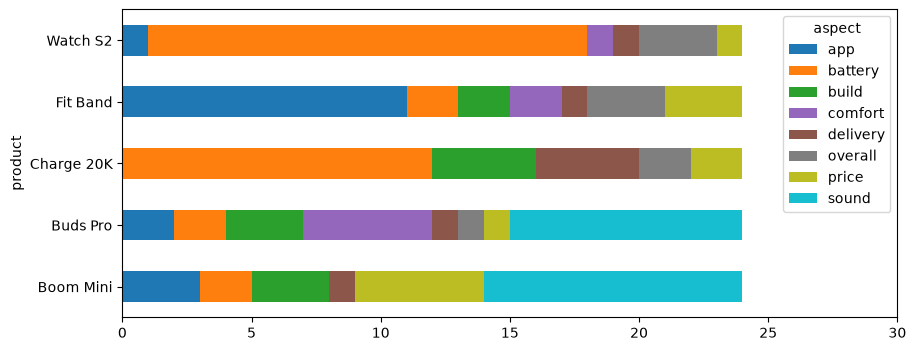

In [16]:
aspects.plot.barh(stacked=True, figsize=(10, 4), xlim=(0, 30), colormap="tab10")

## Dashboard: Sentiment by Month
- Slide 16
- `to_period("M")` turns each date into its month
- `pivot_table` averages `sentiment` per month and product

In [17]:
reviews["month"] = reviews["date"].dt.to_period("M")
by_month = reviews.pivot_table(index="month", columns="product", values="sentiment")
by_month

product,Boom Mini,Buds Pro,Charge 20K,Fit Band,Watch S2
month,,,,,
2026-01,2.9575,2.9400,2.5875,1.6000,3.2375
2026-02,2.4975,2.2575,1.4750,2.2700,3.5500
2026-03,2.6875,2.3175,3.3725,2.3150,3.2900
2026-04,2.6200,2.1275,1.9125,3.0975,0.2820
2026-05,2.0400,2.6050,2.7225,2.8125,1.3050
2026-06,2.9325,2.5000,3.1500,2.4525,2.9850


<Axes: xlabel='month'>

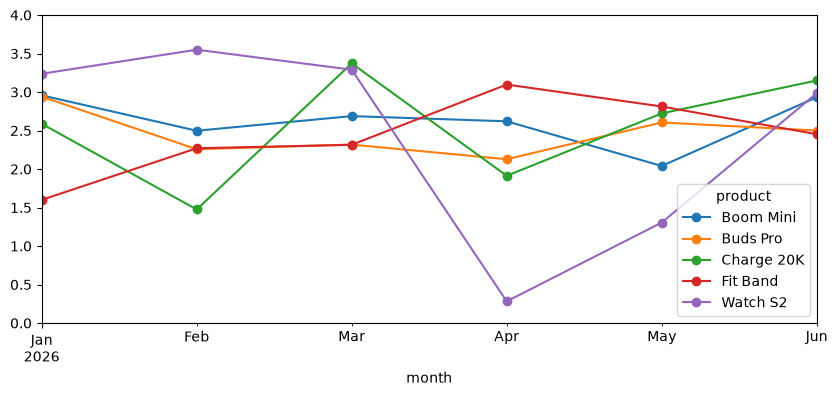

In [18]:
by_month.plot(marker="o", figsize=(10, 4), ylim=(0, 4))

- Which aspects the Watch S2 reviews were about, month by month

In [19]:
watch = reviews[reviews["product"] == "Watch S2"]
pd.crosstab(watch["month"], watch["aspect"])

aspect,app,battery,comfort,delivery,overall,price
month,,,,,,
2026-01,1,2,1,0,0,0
2026-02,0,0,0,0,2,1
2026-03,0,2,0,1,1,0
2026-04,0,5,0,0,0,0
2026-05,0,4,0,0,0,0
2026-06,0,4,0,0,0,0


## Dashboard: Refund Requests
- `refund > 0.5` turns the probability into a yes/no column

<Axes: xlabel='product'>

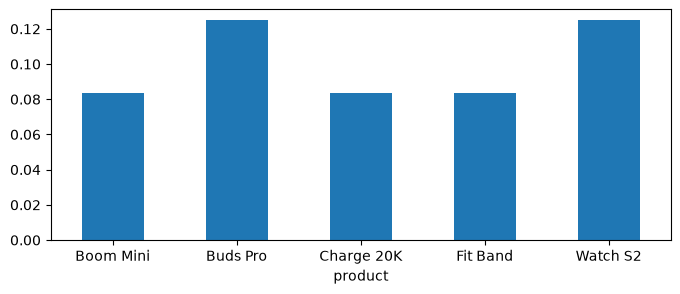

In [20]:
reviews["wants_refund"] = reviews["refund"] > 0.5
reviews.groupby("product")["wants_refund"].mean().plot.bar(figsize=(8, 3), rot=0)

## Dashboard: Competitor Mentions
- Count per product, then read the reviews behind the bars

<Axes: xlabel='product'>

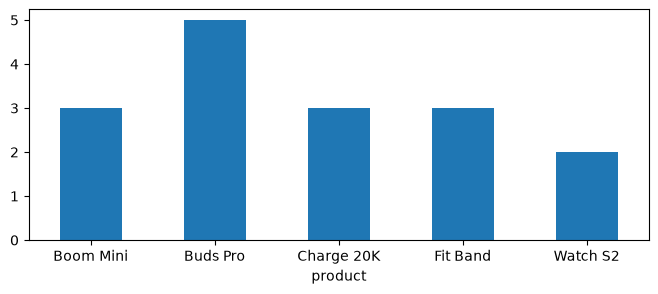

In [21]:
reviews["mentions_competitor"] = reviews["competitor"] > 0.5
reviews.groupby("product")["mentions_competitor"].sum().plot.bar(figsize=(8, 3), rot=0)

In [22]:
reviews[reviews["mentions_competitor"]][["product", "sentiment", "text"]]

,product,sentiment,text
5,Buds Pro,2.89,"Coming from AirPods Pro, these sound better im..."
7,Boom Mini,2.97,"Good sound, decent bass for a small speaker. M..."
10,Fit Band,3.06,"For the price this is great. Tracks steps, sle..."
13,Watch S2,2.98,Switched from a Galaxy Watch. Battery here is ...
31,Buds Pro,3.00,"Pretty good noise cancelling, not quite my old..."
39,Charge 20K,3.70,Better than my Anker which died after a year. ...
49,Charge 20K,3.55,Value for money. Cheaper than the similar Mi a...
56,Buds Pro,3.00,Better than my AirPods in every way except the...
59,Fit Band,3.06,"Comfortable for sleep tracking, unlike my old ..."
67,Charge 20K,0.97,Expensive for what it is. Same capacity is ava...


## Dashboard: One Summary Table
- The mean of a `Noul` column is the expected share of yes

In [23]:
reviews.groupby("product")[["sentiment", "recommend", "refund", "competitor"]].mean()

,sentiment,recommend,refund,competitor
product,,,,
Boom Mini,2.622500,0.576667,0.148750,0.133333
Buds Pro,2.457917,0.566667,0.190417,0.220417
Charge 20K,2.536667,0.565000,0.168750,0.132083
Fit Band,2.424583,0.515417,0.166250,0.133750
Watch S2,2.305417,0.505417,0.182917,0.107083


## Sending Low-Confidence Rows for Human Review
- Slides 17-18
- Lowest `aspect_conf` first: the aspect probabilities were split

In [24]:
reviews.sort_values("aspect_conf")[["product", "aspect", "aspect_conf", "text"]].head(8)

,product,aspect,aspect_conf,text
40,Watch S2,battery,0.33,Solid smartwatch. Battery lasts almost a week....
46,Buds Pro,comfort,0.34,"Oh great, another 'premium' earbud where the t..."
89,Charge 20K,overall,0.42,It's ok. Big and heavy. If you need capacity i...
22,Fit Band,overall,0.44,"Light, comfortable, I forget I'm wearing it. B..."
105,Boom Mini,sound,0.44,"Exactly what I wanted. Loud, small, lasts all ..."
29,Watch S2,price,0.47,Good value. The app is a bit basic but the wat...
24,Watch S2,overall,0.48,"Best watch I've owned. 5+ days battery, GPS lo..."
18,Watch S2,app,0.49,Notifications are delayed sometimes. Otherwise...


In [25]:
uncertain = reviews.sort_values("aspect_conf").index[0]
results[uncertain].answers["aspect"].probabilities

{'battery': 0.4,
 'support': 0.0,
 'price': 0.0,
 'overall': 0.38,
 'comfort': 0.17,
 'app': 0.0,
 'build': 0.05,
 'sound': 0.0,
 'delivery': 0.0}

- A `Noul` near 0.5 is the uncertain zone

In [26]:
reviews[reviews["refund"].between(0.2, 0.8)][["product", "refund", "text"]]

,product,refund,text
0,Fit Band,0.32,Band is comfortable and the battery lasts 2 we...
11,Buds Pro,0.38,left bud keeps falling out when i run. tried a...
19,Charge 20K,0.21,"The LED indicator is useless, 4 dots that jump..."
28,Boom Mini,0.29,Distorts at full volume. If you keep it under ...
30,Charge 20K,0.29,Delivery took 12 days and the box was already ...
37,Boom Mini,0.23,"Good speaker. App is unnecessary, I never open..."
67,Charge 20K,0.20,Expensive for what it is. Same capacity is ava...
70,Fit Band,0.22,Heart rate jumps around during workouts. Fine ...
83,Watch S2,0.39,Still no fix for the battery drain. My old Fit...
85,Watch S2,0.26,The watch is good when it works but with the c...


- The review queue: rows where any answer is unsure

In [27]:
needs_review = (reviews["aspect_conf"] < 0.5) | reviews["refund"].between(0.2, 0.8)
needs_review.sum()

np.int64(20)

## Lab: Lead Scoring
- Slide 19
- `leads.csv`: 40 inbound leads for a helpdesk product
- `note` is written by the lead (web form) or by a sales rep after a call

In [28]:
leads = pd.read_csv("data/leads.csv")
leads.head()

,lead_id,company,role,source,note
0,L01,Brightpath Logistics,Head of Customer Operations,call,Running support for 40 agents out of a shared ...
1,L02,Nimbus Dental Group,Office Manager,web form,just looking around for now. we have 3 people ...
2,L03,Kestrel Fintech,VP Engineering,call,Evaluating 3 vendors including Zendesk. Hard r...
3,L04,Hartwell University,IT Intern,web form,Hi! I'm doing some research for my manager on ...
4,L05,Orchid Home Furnishings,Founder & CEO,call,"E-commerce, about 12k orders a month. Return e..."


## One Question per Factor: Budget, Need, Timeline, Authority
- Slide 20
- Three `Score`s with four levels each, and one `Noul`
- Instructions name the state fields in backticks

In [29]:
BUDGET = Score(
    instructions="How strong is the budget signal in `note`?",
    criteria=[
        "no budget, or asks for a free or the cheapest option",
        "budget unknown or not yet allocated",
        "budget planned but needs approval or a later fiscal year",
        "budget approved and stated",
    ],
)
NEED = Score(
    instructions="How strong is the need for a helpdesk product in `note`?",
    criteria=[
        "just curious or researching, no problem described",
        "general interest, problem is vague",
        "a clear problem that a helpdesk product solves",
        "a painful problem that is costing them customers or money now",
    ],
)
TIMELINE = Score(
    instructions="How soon does this lead want to buy, based on `note`?",
    criteria=[
        "no timeline, or more than 6 months away",
        "within 3 to 6 months",
        "within 1 to 3 months",
        "within weeks, or a hard deadline",
    ],
)
DECISION_MAKER = Noul(
    instructions="The person in `role` can approve this purchase, "
                 "alone or as the lead decision maker, based on `note`.",
)

LEAD_QUESTIONS = {
    "budget": BUDGET,
    "need": NEED,
    "timeline": TIMELINE,
    "decision_maker": DECISION_MAKER,
}

## Scoring a Single Lead
- State is a dict: `role` and `note` together

In [30]:
states = leads[["role", "note"]].to_dict("records")
states[0]

{'role': 'Head of Customer Operations',
 'note': 'Running support for 40 agents out of a shared Gmail inbox, tickets get lost every day. Has an approved budget of around $60k a year. Wants to be live before the Q1 peak season. She signs off on tooling herself.'}

In [31]:
client.system_one(states[0], LEAD_QUESTIONS).answers

{'budget': ScoreAnswer(type='score', score=3.0, confidence=1.0, legend={0: 'no budget, or asks for a free or the cheapest option', 1: 'budget unknown or not yet allocated', 2: 'budget planned but needs approval or a later fiscal year', 3: 'budget approved and stated'}, probabilities={0: 0.0, 1: 0.0, 2: 0.0, 3: 1.0}),
 'need': ScoreAnswer(type='score', score=2.88, confidence=0.88, legend={0: 'just curious or researching, no problem described', 1: 'general interest, problem is vague', 2: 'a clear problem that a helpdesk product solves', 3: 'a painful problem that is costing them customers or money now'}, probabilities={0: 0.0, 1: 0.0, 2: 0.12, 3: 0.88}),
 'timeline': ScoreAnswer(type='score', score=2.0, confidence=0.51, legend={0: 'no timeline, or more than 6 months away', 1: 'within 3 to 6 months', 2: 'within 1 to 3 months', 3: 'within weeks, or a hard deadline'}, probabilities={0: 0.0, 1: 0.24, 2: 0.51, 3: 0.25}),
 'decision_maker': NoulAnswer(type='noul', noul=0.89)}

## Scoring All Leads on a 0 to 1 Scale
- A four-level `Score` runs from 0 to 3, so divide by 3
- A `Noul` is already 0 to 1

In [32]:
lead_results = await asyncio.gather(
    *[aclient.system_one(s, LEAD_QUESTIONS) for s in states]
)

leads["budget"] = [r.answers["budget"].score / 3 for r in lead_results]
leads["need"] = [r.answers["need"].score / 3 for r in lead_results]
leads["timeline"] = [r.answers["timeline"].score / 3 for r in lead_results]
leads["decision_maker"] = [r.answers["decision_maker"].noul for r in lead_results]
leads[["company", "role", "budget", "need", "timeline", "decision_maker"]].head()

,company,role,budget,need,timeline,decision_maker
0,Brightpath Logistics,Head of Customer Operations,1.000000,0.973333,0.690000,0.90
1,Nimbus Dental Group,Office Manager,0.276667,0.073333,0.003333,0.28
2,Kestrel Fintech,VP Engineering,0.946667,0.350000,0.643333,0.22
3,Hartwell University,IT Intern,0.270000,0.003333,0.063333,0.03
4,Orchid Home Furnishings,Founder & CEO,0.223333,0.986667,1.000000,0.85


## Combining Factor Scores With Weights
- Slide 21
- The weights sum to 1, so `lead_score` stays between 0 and 1

In [33]:
leads["lead_score"] = (
    0.30 * leads["budget"]
    + 0.25 * leads["need"]
    + 0.25 * leads["timeline"]
    + 0.20 * leads["decision_maker"]
)
ranked = leads.sort_values("lead_score", ascending=False)
ranked[["company", "role", "budget", "need", "timeline", "decision_maker", "lead_score"]]

,company,role,budget,need,timeline,decision_maker,lead_score
11,Lumen Edtech,Co-founder & CTO,0.873333,0.960000,1.000000,0.93,0.938000
9,Sundial Travel,Head of CX,1.000000,1.000000,0.986667,0.59,0.914667
0,Brightpath Logistics,Head of Customer Operations,1.000000,0.973333,0.690000,0.90,0.895833
16,Vertex Cloud Hosting,Director of Support,1.000000,0.693333,0.906667,0.91,0.882000
39,Monsoon Airlines,"Senior Manager, Contact Centre",0.986667,0.930000,1.000000,0.46,0.870500
34,Nova Diagnostics,Head of Patient Support,0.993333,0.986667,0.996667,0.36,0.865833
13,Aster Pharmacy Chain,VP Customer Experience,0.993333,0.556667,0.993333,0.88,0.861500
19,Saffron Foods Delivery,Head of Operations,1.000000,0.836667,1.000000,0.48,0.855167
28,Mango Mobile,Head of Customer Care,0.996667,0.656667,0.693333,0.78,0.792500
31,Silverline Logistics,COO,0.526667,0.733333,0.970000,0.86,0.755833


- What each part adds to the top 10 scores

<Axes: ylabel='company'>

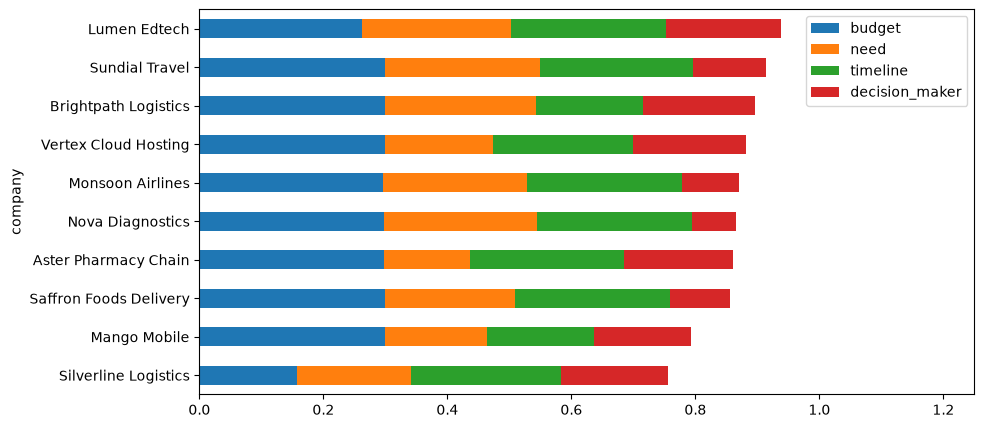

In [34]:
top = leads.sort_values("lead_score").tail(10).set_index("company")[
    ["budget", "need", "timeline", "decision_maker"]
]
(top * [0.30, 0.25, 0.25, 0.20]).plot.barh(stacked=True, figsize=(10, 5), xlim=(0, 1.25))

## Changing Weights to Re-Rank Leads
- Slides 22-23, covering the Composite Scoring Pattern too
- A quarter-end push: timeline counts most
- Same answers, no new API calls

In [35]:
leads["quarter_end_score"] = (
    0.15 * leads["budget"]
    + 0.15 * leads["need"]
    + 0.50 * leads["timeline"]
    + 0.20 * leads["decision_maker"]
)
leads.sort_values("quarter_end_score", ascending=False)[
    ["company", "timeline", "lead_score", "quarter_end_score"]
].head(10)

,company,timeline,lead_score,quarter_end_score
11,Lumen Edtech,1.000000,0.938000,0.961000
9,Sundial Travel,0.986667,0.914667,0.911333
13,Aster Pharmacy Chain,0.993333,0.861500,0.905167
16,Vertex Cloud Hosting,0.906667,0.882000,0.889333
39,Monsoon Airlines,1.000000,0.870500,0.879500
19,Saffron Foods Delivery,1.000000,0.855167,0.871500
34,Nova Diagnostics,0.996667,0.865833,0.867333
4,Orchid Home Furnishings,1.000000,0.733667,0.851500
31,Silverline Logistics,0.970000,0.755833,0.846000
20,Polaris Legal LLP,0.990000,0.752667,0.828000


In [36]:
leads.to_csv("data/leads_scored.csv", index=False)

## Cheat Sheet
| Need | Code |
|---|---|
| A category column | `Choice(instructions, criteria={label: description})` then `.choice` |
| Its data-quality column | `.confidence` |
| An ordered number column | `Score(instructions, criteria=[level0, ...])` then `.score` |
| A probability column | `Noul(instructions)` then `.noul` |
| All columns in one request | `client.system_one(text, {"col": question, ...})` |
| Every row at once | `await asyncio.gather(*[aclient.system_one(x, QUESTIONS) for x in texts])` |
| Answers into pandas | `df["col"] = [r.answers["col"].choice for r in results]` |
| Counts per group | `pd.crosstab(df["product"], df["aspect"])` |
| Mean per month | `df.pivot_table(index="month", columns="product", values="sentiment")` |
| Yes/no from a probability | `df["refund"] > 0.5` |
| Rows for a person | `df[df["aspect_conf"] < 0.5]`, `df["refund"].between(0.2, 0.8)` |
| Score to 0 to 1 | `.score / (number of levels - 1)` |
| Composite score | `w1 * df["a"] + w2 * df["b"] + ...` with weights that sum to 1 |

## Wrap-Up
- Slide 24: text to columns across industries